In [1]:
from pathlib import Path
import pandas as pd
import plotly.express as px

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
regions = pd.read_csv(ROOT / "data" / "processed" / "regions_2024.csv") # table we cleaned
regions.shape

(49, 10)

In [2]:
cols = ["median_wait_days", "family_docs_per_100k", "specialists_per_100k"]
regions[cols].describe().round(1)

,median_wait_days,family_docs_per_100k,specialists_per_100k
count,49.0,49.0,49.0
mean,170.2,125.0,105.0
std,84.9,28.8,54.6
min,31.0,81.8,23.1
25%,107.0,104.3,72.0
50%,156.0,119.6,93.0
75%,217.0,140.5,130.0
max,422.0,225.3,245.9


In [3]:
regions[cols].corr().round(2)

,median_wait_days,family_docs_per_100k,specialists_per_100k
median_wait_days,1.00,-0.18,-0.16
family_docs_per_100k,-0.18,1.00,0.44
specialists_per_100k,-0.16,0.44,1.00


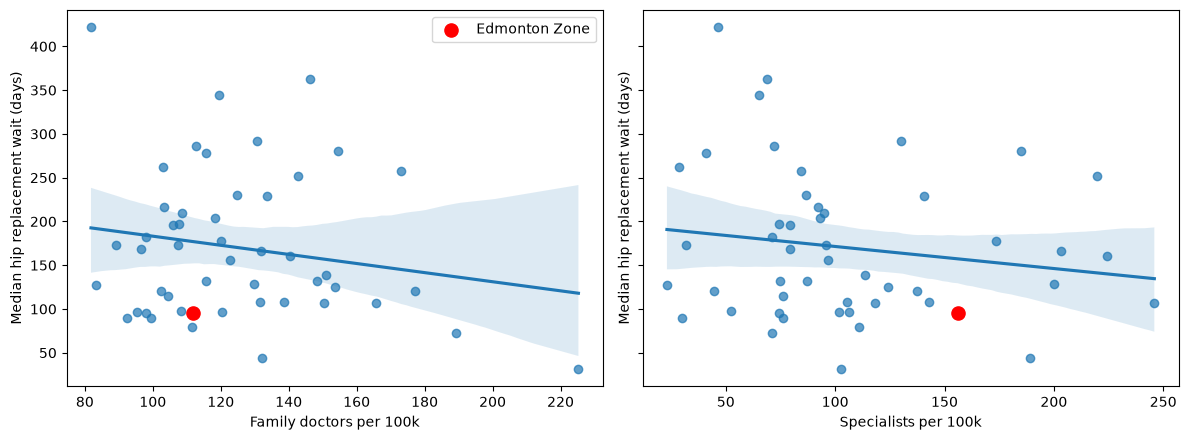

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
edmonton = regions[regions["region"] == "Edmonton Zone"]

for ax, col, label in zip(
    axes,
    ["family_docs_per_100k", "specialists_per_100k"],
    ["Family doctors per 100k", "Specialists per 100k"],
):
    sns.regplot(data=regions, x=col, y="median_wait_days", ax=ax, scatter_kws={"alpha": 0.7})
    ax.scatter(edmonton[col], edmonton["median_wait_days"], color="red", s=90, zorder=3, label="Edmonton Zone")
    ax.set_xlabel(label)
    ax.set_ylabel("Median hip replacement wait (days)")

axes[0].legend()
plt.tight_layout()
fig.savefig(ROOT / "reports" / "figures" / "waits_vs_doctors.png", dpi=150)
plt.show()

In [6]:
regions.nlargest(3, "family_docs_per_100k")[["province", "region", "family_docs_per_100k", "specialists_per_100k", "median_wait_days"]]

,province,region,family_docs_per_100k,specialists_per_100k,median_wait_days
35,Quebec,Gaspésie–Îles-de-la-Madeleine Region,225.264252,102.885115,31.0
33,Quebec,Côte-Nord Region,189.212653,71.232999,73.0
7,British Columbia,Island Health,177.273572,137.300119,121.0


In [7]:
no_gaspesie = regions[~regions["region"].str.startswith("Gasp")]
no_gaspesie[cols].corr().round(2)

,median_wait_days,family_docs_per_100k,specialists_per_100k
median_wait_days,1.00,-0.07,-0.17
family_docs_per_100k,-0.07,1.00,0.51
specialists_per_100k,-0.17,0.51,1.00


## Exploratory analysis: what I did and found

### What I did
1. Cleaned and joined two CIHI datasets: 2024 hip replacement waits and 2024 physician supply, 
   across 49 health regions. Matching them took some work: names were spelled differently, 
   BC's 16 small areas had to be combined into 5 health authorities, and New Brunswick was left 
   out because its regions don't line up between the two sources.
2. Summarised each measure to check for gaps and odd values.
3. Checked how strongly doctor supply is related to waits (correlation), and plotted it with 
   Edmonton highlighted.
4. Tested whether one unusual region was driving the result, by re-running without it.

### What I found
- **Waits vary a lot across Canada.** A typical region waits about 5 months (156 days) for a hip 
  replacement, but it ranges from about 1 month to over a year. The longest waits are mostly 
  in rural and remote regions.
- **Doctor supply barely explains it.** Specialists per 100k has a weak link to waits (-0.17). 
  Family doctors per 100k looked related at first (-0.18), but that came from one small, remote 
  Quebec region (Gaspésie). Without it the link is basically zero (-0.07).
- **Regions with the same number of doctors have very different waits**, so something other 
  than headcount matters.
- **Edmonton does well.** It waits about 3 months (95 days), 7th shortest of 49 regions, and the 
  best in Alberta, with 79% of patients treated within the 6-month benchmark. It has lots of 
  specialists, but waits less than doctor numbers alone would predict.

### What this means for the next step
Doctor headcount is not enough to explain who waits longest. The model needs other factors: 
whether people have a regular doctor, how old and how rural the population is, and how many 
surgeries the region performs per person.

